# 1 · Data and flux estimates

Over Arctic sea ice, the turbulent sensible heat flux $H_\mathrm{S}$ is commonly estimated with a bulk formula
driven by reanalysis data. Assessing such estimates requires a measured reference. During BACSAM-II (Svalbard,
April 2024), the **T-Bird**, a sensor package towed about 24 m above the ice below the research aircraft Polar 6,
sampled wind and temperature at 100 Hz, from which the flux is obtained by **eddy covariance (EC)**.

All estimates are evaluated on the same 5 km flight segments:

| Symbol | Method | Inputs |
|---|---|---|
| $H_\mathrm{S,obs,EC}$ | eddy covariance (**reference**) | 100 Hz $w$, $\theta$ from the T-Bird |
| $H_\mathrm{S,obs,bulk}$ | bulk formula | measured: KT-19 surface temperature, T-Bird air temperature, wind and pressure |
| $H_\mathrm{S,RS,bulk}$ | bulk formula | MODIS surface temperature (ERA5 skin temperature under cloud) and ERA5 air temperature, wind and pressure at the model level closest to the T-Bird |
| $H_\mathrm{S,ERA,bulk}$ | bulk formula | ERA5 only |
| $H_\mathrm{S,ERA,diag}$, $H_\mathrm{S,CAR,diag}$ | model output | surface flux diagnosed by ERA5 and CARRA |

From top to bottom, measured inputs are successively replaced by products with pan-Arctic coverage, so that a
loss of skill can be attributed to the replaced input.

The chapters follow the paper: the EC reference (2), the bulk method (3), the comparison (4), and sensitivity and
uncertainty (5).

> [!NOTE]
> All numbers are computed from the files in `data/` with the `fluxpy` functions that produce the paper, and hand
> calculations are checked against the pipeline output. Symbols are defined in the [glossary](../docs/glossary.md).
> The notebooks can be run in Jupyter from the `book/` folder (`pixi run jupyter lab`).
>
> **Paper:** Sects. 1–2, Table 1, Fig. 1. **Code:** `scripts/calc_bulk_and_ec_fluxes.py` evaluates all six
> estimates on the segments and writes `data/model_output/sensitivity_figure_data.nc`, which this chapter reads.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
REPO = Path("..").resolve(); sys.path.insert(0, str(REPO))
plt.rcParams.update({"figure.dpi": 110, "figure.constrained_layout.use": True, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

AR  = REPO / "data/observations/ar"
FIG = xr.open_dataset(REPO / "data/model_output/sensitivity_figure_data.nc")      # all flux estimates, 90 segments
SEG = xr.open_dataset(AR / "analysis_ready_polar6_turbulent_fluxes_latest_5km.nc").sel(start_time=FIG.start_time.values)
EC  = FIG["H_obs_ec"].values

## Segments

The analysis uses the constant-altitude legs flown over sea ice with the T-Bird below 50 m; within a segment the
T-Bird height varies by less than 30 m (paper Sect. 2.1 and Appendix A1). The low-level legs of 25 April were flown
over open water and are excluded.

In [2]:
t = pd.to_datetime(SEG.start_time.values)
tab = pd.DataFrame({"segments": 1, "T-Bird height (m)": SEG.altitude.values,
                    "EC flux (W m-2)": EC, "KT-19 surface temp. (degC)": SEG.t_kt19.values}, index=t)
g = tab.groupby(tab.index.strftime("%d %B"))
out = g.agg({"segments": "sum", "T-Bird height (m)": "mean", "EC flux (W m-2)": "median", "KT-19 surface temp. (degC)": "mean"}).round(1)
print(f"{len(tab)} segments of 5 km = {5 * len(tab)} km of low-level flight\n"); out

90 segments of 5 km = 450 km of low-level flight



,segments,T-Bird height (m),EC flux (W m-2),KT-19 surface temp. (degC)
13 April,17,20.7,0.2,-25.1
15 April,22,22.1,6.5,-17.1
17 April,26,29.1,0.2,-16.6
23 April,25,21.1,0.0,-2.0


The fluxes are small: over compact sea ice in spring, surface and air temperatures are nearly equal. With fluxes of
a few W m⁻², an estimate of zero everywhere already has a small error. The estimates are therefore assessed by the
*amplitude* they recover (regression slope) and by their *correlation* with the reference, not by the RMSE (Chapter 4).

median 0.4 W m-2, 56 % of the segments within +-2 W m-2


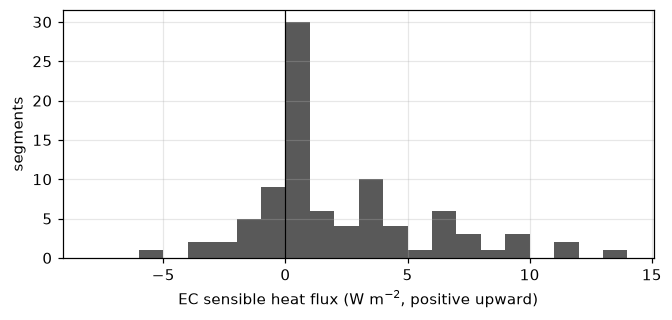

In [3]:
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.hist(EC[np.isfinite(EC)], bins=np.arange(-8, 15, 1), color="0.35")
ax.axvline(0, color="k", lw=0.8); ax.set_xlabel("EC sensible heat flux (W m$^{-2}$, positive upward)"); ax.set_ylabel("segments")
print(f"median {np.nanmedian(EC):.1f} W m-2, {np.mean(np.abs(EC[np.isfinite(EC)]) < 2) * 100:.0f} % of the segments within +-2 W m-2")

Flight tracks (Fig. 1):

![Fig. 1](../figures_manuscript/output/fig01_campaign_overview.png)